# Bayesian update schematic: prior + likelihood $\rightarrow$ posterior

This notebook creates a simple schematic for the Bayesian update

\[
p(\theta \mid D)\propto p(D\mid \theta)\,p(\theta).
\]

We use a **Beta prior** together with a **Binomial likelihood** for a coin-flip example.

If we observe \(h\) heads in \(n\) flips, then

\[
p(D\mid \theta)\propto \theta^h(1-\theta)^{n-h}.
\]

If the prior is

\[
\theta \sim \operatorname{Beta}(\alpha,\beta),
\]

then the posterior is

\[
\theta\mid D \sim \operatorname{Beta}(\alpha+h,\beta+n-h).
\]

The goal of the notebook is to visualize, in a schematic way, how the prior and likelihood combine to give the posterior.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Example parameters
alpha = 2
beta_param = 6

n = 10
h = 7
t = n - h

theta = np.linspace(1e-4, 1 - 1e-4, 1000)

# Prior density
prior = beta.pdf(theta, alpha, beta_param)

# Likelihood as a function of theta, up to proportionality
likelihood = theta**h * (1 - theta)**t

# Posterior density
posterior = beta.pdf(theta, alpha + h, beta_param + t)

# For plotting, rescale likelihood so that it is visually comparable
likelihood_scaled = likelihood / likelihood.max() * prior.max()

print(f"Prior: Beta({alpha}, {beta_param})")
print(f"Data: h = {h} heads, t = {t} tails")
print(f"Posterior: Beta({alpha+h}, {beta_param+t})")

Prior: Beta(2, 6)
Data: h = 7 heads, t = 3 tails
Posterior: Beta(9, 9)


## 1. Prior distribution

The prior represents our beliefs about \(\theta\) before seeing the current data.

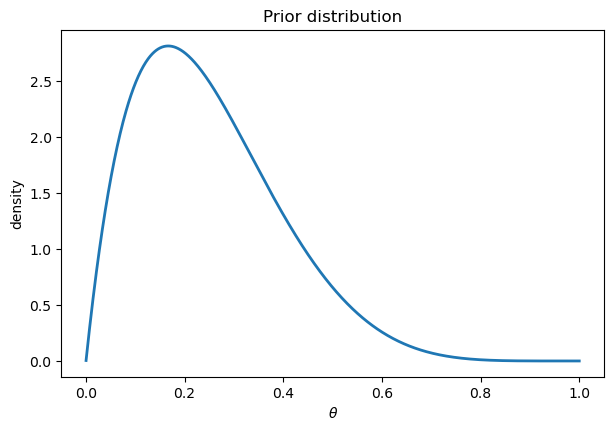

In [22]:
plt.figure(figsize=(7, 4.5))
plt.plot(theta, prior, linewidth=2)
plt.xlabel(r"$\theta$")
plt.ylabel("density")
plt.title("Prior distribution")
plt.show()

## 2. Likelihood function

The likelihood is a function of \(\theta\) for the observed data \(D\).

For \(h\) heads in \(n\) flips,

\[
L(\theta)=p(D\mid \theta)\propto \theta^h(1-\theta)^{n-h}.
\]

For visualization, we rescale the likelihood vertically. This scaling does **not** change where it is large or small.

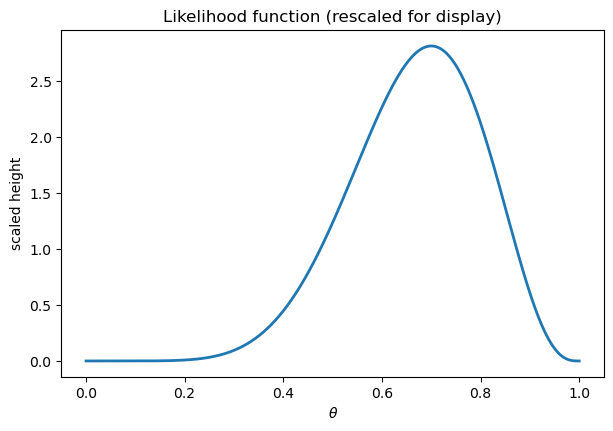

In [23]:
plt.figure(figsize=(7, 4.5))
plt.plot(theta, likelihood_scaled, linewidth=2)
plt.xlabel(r"$\theta$")
plt.ylabel("scaled height")
plt.title("Likelihood function (rescaled for display)")
plt.show()

## 3. Posterior distribution

The posterior combines the prior and the likelihood:

\[
p(\theta\mid D)\propto p(D\mid\theta)\,p(\theta).
\]

For the Beta-Binomial pair, the posterior is again Beta.

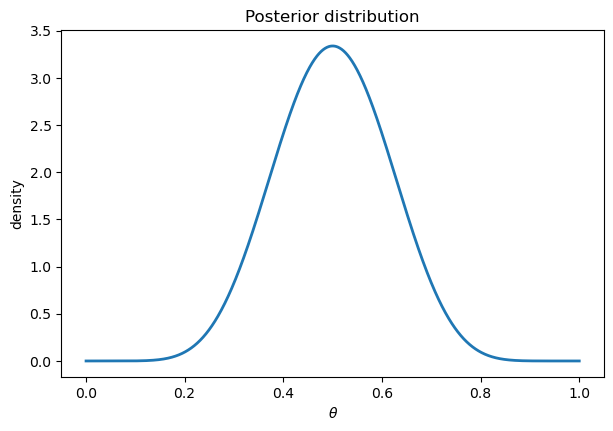

In [24]:
plt.figure(figsize=(7, 4.5))
plt.plot(theta, posterior, linewidth=2)
plt.xlabel(r"$\theta$")
plt.ylabel("density")
plt.title("Posterior distribution")
plt.show()

## 4. Schematic overlay: prior, likelihood, posterior

This is the main schematic figure.

It shows:

- the **prior** \(p(\theta)\),
- the **likelihood** \(p(D\mid\theta)\) (rescaled for plotting),
- the **posterior** \(p(\theta\mid D)\).

The posterior is shifted toward parameter values that are supported by both the prior and the data.

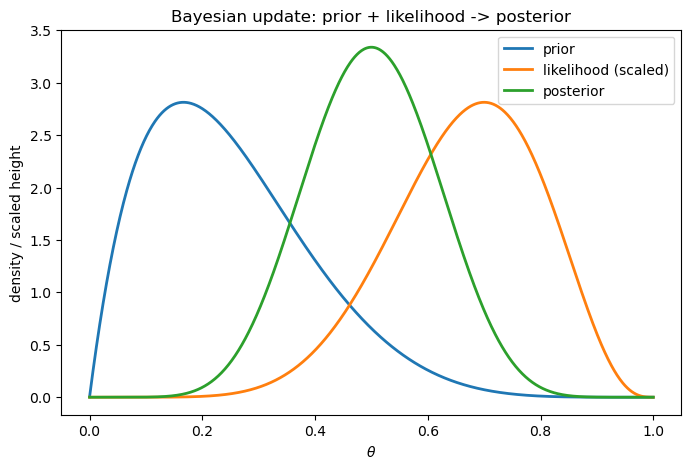

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(theta, prior, linewidth=2, label="prior")
plt.plot(theta, likelihood_scaled, linewidth=2, label="likelihood (scaled)")
plt.plot(theta, posterior, linewidth=2, label="posterior")
plt.xlabel(r"$\theta$")
plt.ylabel("density / scaled height")
plt.title("Bayesian update: prior + likelihood -> posterior")
plt.legend()
plt.savefig('bayesian-schematic.png',dpi=300)

## 5. Product view

To make the update even more explicit, we can look at the unnormalized product

\[
p(D\mid\theta)\,p(\theta).
\]

After normalization, this becomes the posterior.

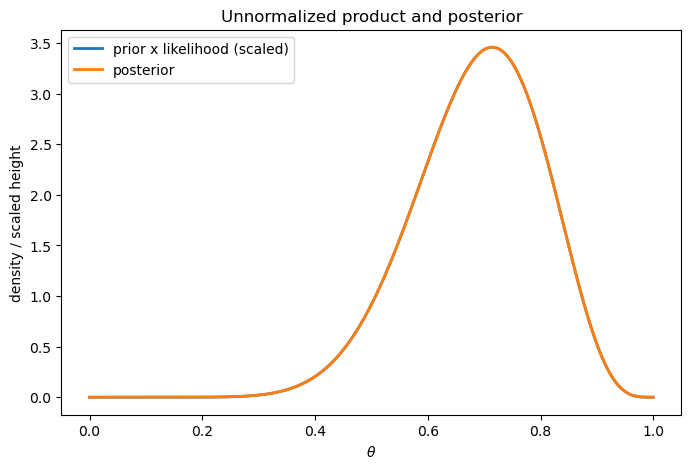

In [13]:
unnormalized_posterior = prior * likelihood
unnormalized_scaled = (
    unnormalized_posterior / unnormalized_posterior.max() * posterior.max()
)

plt.figure(figsize=(8, 5))
plt.plot(theta, unnormalized_scaled, linewidth=2, label="prior x likelihood (scaled)")
plt.plot(theta, posterior, linewidth=2, label="posterior")
plt.xlabel(r"$\theta$")
plt.ylabel("density / scaled height")
plt.title("Unnormalized product and posterior")
plt.legend()
plt.show()

## 6. Optional: change the parameters

You can change:

- `alpha`, `beta_param` for the prior,
- `n`, `h` for the data,

and rerun the notebook to see how the schematic changes.

For example:

- stronger prior belief,
- fewer data,
- more data,
- data that agree or disagree with the prior.